# 🚗 Real-Time Vehicle Accident Detection — TinyML Training Pipeline

এই notebook-এ পুরো **training pipeline** end-to-end দেখানো হয়েছে:

1. **Data** — MPU6050-style sensor data (100 Hz) simulate/load করা
2. **Visualize** — প্রতিটি scenario-র signal plot
3. **Features** — 1 s window (50% overlap) থেকে 12টি sensor-fusion feature
4. **Train** — Autoencoder (primary, default) + Classifier (optional)
5. **Evaluate** — confusion matrix, precision/recall
6. **Convert** — full **int8** post-training quantization (TFLite)
7. **Compare** — float vs int8 accuracy
8. **Export** — `model_data.h/.cc` + `model_config.h` (TFLite Micro, ESP32-S3)

> ⚠️ **Disclaimer:** simulated data আসল crash data **না**। এই model শুধু pipeline demo; বাস্তবে real sensor measurement দিয়ে আবার retrain করতে হবে।

Notebook-টি `notebooks/` folder থেকে চালাতে হবে (VS Code / Jupyter), project root স্বয়ংক্রিয়ভাবে খুঁজে নেয়।

In [1]:
import os, sys, json, warnings
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
if not (ROOT / "scripts").exists():          # notebook is inside notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

import features as F
from collect_data import simulate_dataset, save_csv
from train import run_training
from convert_tflite import run_conversion

pd.set_option("display.width", 160, "display.max_columns", 20)
print("project root:", ROOT)
print("features:", F.N_FEATURES, F.FEATURE_NAMES)

project root: /workspace/accident-ml
features: 12 ['acc_mag_mean', 'acc_mag_std', 'acc_mag_max', 'jerk_max', 'gyro_mag_mean', 'gyro_mag_max', 'tilt_deg', 'temp_mean', 'temp_slope', 'vib_mean', 'vib_rms', 'vib_peak']


## 1️⃣ Data — simulate বা load

`data/raw/sample_sessions.csv` থাকলে সেটি load হবে (repo-তে sample দেওয়া আছে)। না থাকলে একই seed দিয়ে simulate করে save করা হবে।

Command line equivalent:
```bash
python scripts/collect_data.py --sessions 24 --duration 40 --seed 7 --out data/raw/sample_sessions.csv
```
Columns: `session_id, timestamp_ms, ax, ay, az (g), gx, gy, gz (deg/s), temperature (°C), vibration (0..1), label, scenario`

In [2]:
RAW = ROOT / "data/raw/sample_sessions.csv"
if RAW.exists():
    df = pd.read_csv(RAW)
    print("loaded", RAW.name)
else:
    df = simulate_dataset(sessions=24, duration=40, seed=7)
    save_csv(df, RAW)
print(f"{len(df):,} samples, {df.session_id.nunique()} sessions, {len(df)/F.FS/60:.1f} min @ {F.FS} Hz")
display(df.head())
display(df.label.value_counts().to_frame("samples"))

loaded sample_sessions.csv
96,000 samples, 24 sessions, 16.0 min @ 100 Hz


,session_id,timestamp_ms,ax,ay,az,gx,gy,gz,temperature,vibration,label,scenario
0,0,0,0.0539,-0.0716,1.0323,0.3794,-0.0033,-0.0227,26.2500,0.1811,normal,turning
1,0,10,0.0349,-0.0750,1.0134,0.6129,0.1250,0.3678,26.3125,0.1416,normal,turning
2,0,20,0.0515,-0.0675,1.0047,0.6250,-0.3304,-0.1602,26.2500,0.0659,normal,turning
3,0,30,0.0471,-0.0813,0.9801,0.2266,0.2501,0.0827,26.1875,0.1342,normal,turning
4,0,40,0.0567,-0.0781,0.9858,0.4359,-0.2238,-0.3083,26.2500,0.1468,normal,turning


,samples
label,
normal,81315
rollover,7117
abnormal_temp,7068
crash,500


## 2️⃣ Signals per scenario

প্রতিটি event type-এর একটি session plot করা হলো। Shaded অংশ = labeled event।
- **crash** → খুব ছোট (30–150 ms) high-g spike (4–15 g), gyro kick, vibration burst
- **rollover** → gravity vector ঘুরে যায় (az ↓, ay ↑), gyro rate বেশি, তারপর sustained tilt
- **abnormal_temp** → temperature দ্রুত বাড়ে (engine fire)
- **normal** → idle, cruising, braking, turning, bumpy road (pothole ≈ 1–2 g)

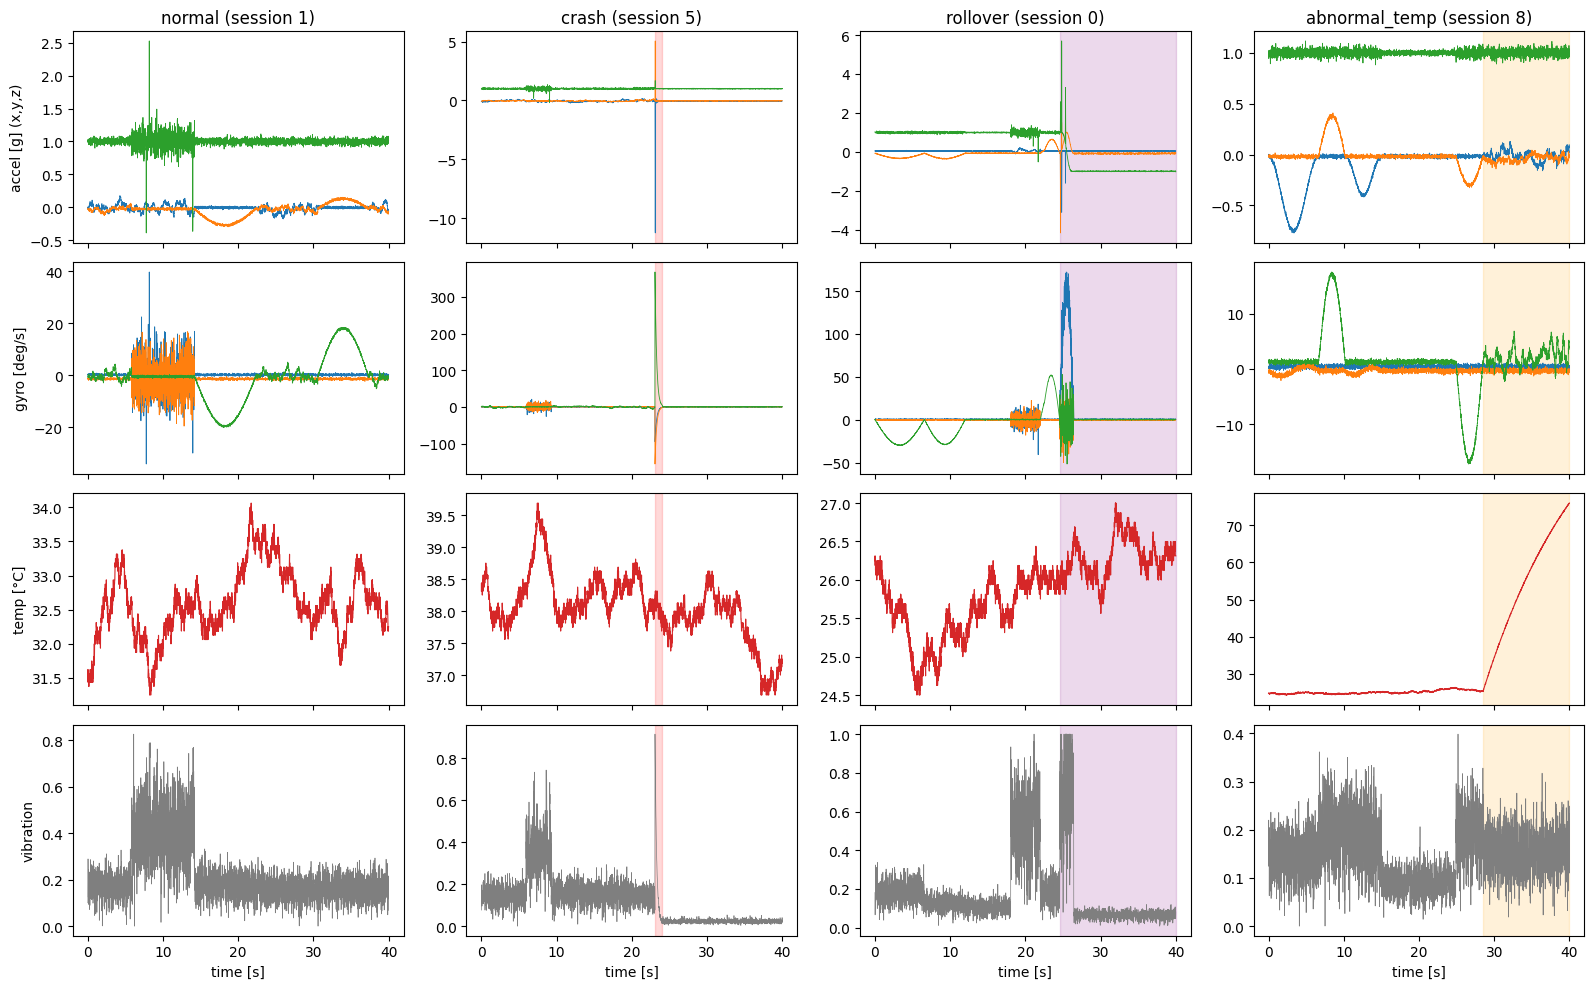

In [3]:
def session_type(s):
    for ev in ["crash", "rollover", "abnormal_temp"]:
        if (s.label == ev).any():
            return ev
    return "normal"

types = df.groupby("session_id").apply(session_type, include_groups=False)
colors = {"crash": "red", "rollover": "purple", "abnormal_temp": "orange"}
fig, axes = plt.subplots(4, 4, figsize=(16, 10), sharex="col")
for c, ev in enumerate(["normal", "crash", "rollover", "abnormal_temp"]):
    sid = types[types == ev].index[0]
    s = df[df.session_id == sid]
    t = s.timestamp_ms / 1000
    axes[0, c].plot(t, s[["ax", "ay", "az"]], lw=0.6); axes[0, c].set_title(f"{ev} (session {sid})")
    axes[1, c].plot(t, s[["gx", "gy", "gz"]], lw=0.6)
    axes[2, c].plot(t, s.temperature, color="tab:red", lw=0.8)
    axes[3, c].plot(t, s.vibration, color="tab:gray", lw=0.5)
    for r in range(4):
        m = (s.label != "normal").to_numpy()
        if m.any():
            axes[r, c].axvspan(t[m].min(), t[m].max(), color=colors[ev], alpha=0.15)
for r, name in enumerate(["accel [g] (x,y,z)", "gyro [deg/s]", "temp [°C]", "vibration"]):
    axes[r, 0].set_ylabel(name)
for a in axes[-1]:
    a.set_xlabel("time [s]")
plt.tight_layout(); plt.show()

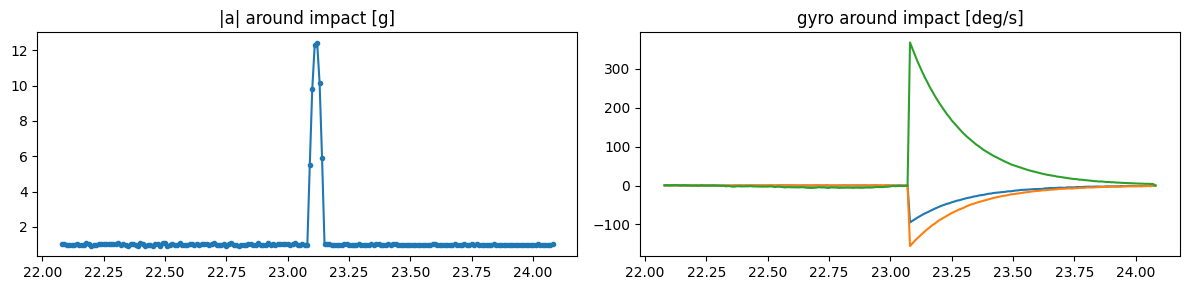

In [4]:
# zoom: crash impact (±1 s) — spike মাত্র কয়েক sample চওড়া, তাই 100 Hz দরকার
s = df[df.session_id == types[types == "crash"].index[0]]
i0 = s.index[(s.label == "crash").to_numpy()][0]
z = df.loc[i0 - 100:i0 + 100]
amag = np.sqrt(z.ax**2 + z.ay**2 + z.az**2)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(z.timestamp_ms / 1000, amag, ".-"); ax[0].set_title("|a| around impact [g]")
ax[1].plot(z.timestamp_ms / 1000, z[["gx", "gy", "gz"]]); ax[1].set_title("gyro around impact [deg/s]")
plt.tight_layout(); plt.show()

## 3️⃣ Feature extraction (sensor fusion)

`scripts/features.py` — training, conversion আর notebook সবাই একই code ব্যবহার করে, তাই ESP32-তেও **হুবহু একই formula** port করতে হবে।

| # | feature | formula |
|---|---|---|
| 0–2 | `acc_mag_mean/std/max` | \|a\| = √(ax²+ay²+az²) |
| 3 | `jerk_max` | max\|Δ\|a\|\| × fs |
| 4–5 | `gyro_mag_mean/max` | \|ω\| = √(gx²+gy²+gz²) |
| 6 | `tilt_deg` | acos(mean_az / \|mean_a\|) |
| 7–8 | `temp_mean`, `temp_slope` | (T_last − T_first)·fs/(N−1) |
| 9–11 | `vib_mean/rms/peak` | RMS = √mean((v−v̄)²) |

Window = 100 samples (1 s), step = 50 (0.5 s)। কোনো event window-এর ≥25% হলে সেই label; সামান্য ছুঁয়ে গেলে (`ambiguous`) training থেকে বাদ।

In [5]:
fx = F.extract_features(df)
(ROOT / "data/processed").mkdir(parents=True, exist_ok=True)
fx.to_csv(ROOT / "data/processed/features.csv", index=False, float_format="%.5f")
print(len(fx), "windows"); display(fx.label.value_counts().to_frame("windows"))
display(fx[fx.label != F.AMBIGUOUS].groupby("label")[F.FEATURE_NAMES].median().round(2))

1896 windows


,windows
label,
normal,1588
rollover,142
abnormal_temp,142
crash,16
ambiguous,8


,acc_mag_mean,acc_mag_std,acc_mag_max,jerk_max,gyro_mag_mean,gyro_mag_max,tilt_deg,temp_mean,temp_slope,vib_mean,vib_rms,vib_peak
label,,,,,,,,,,,,
abnormal_temp,1.0,0.03,1.07,10.990000,1.300000,2.750000,3.400000,62.380001,3.60,0.15,0.04,0.25
crash,1.3,1.61,10.16,248.490005,58.099998,220.110001,17.670000,25.629999,-0.03,0.22,0.20,0.90
normal,1.0,0.03,1.09,11.270000,1.540000,3.270000,4.150000,30.680000,0.00,0.16,0.05,0.28
rollover,1.0,0.01,1.03,4.010000,0.610000,1.190000,131.470001,31.520000,0.00,0.06,0.02,0.10


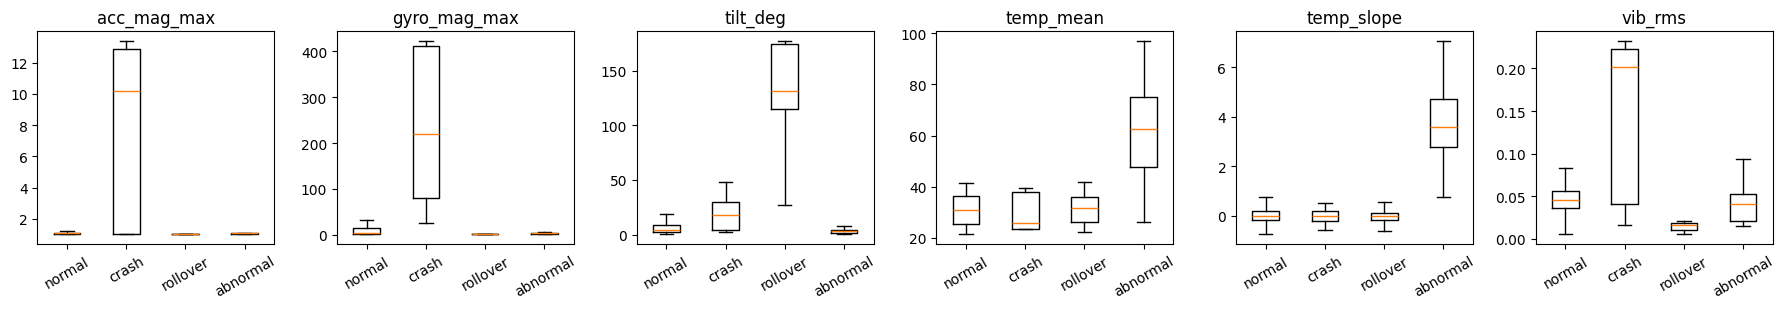

In [6]:
show = ["acc_mag_max", "gyro_mag_max", "tilt_deg", "temp_mean", "temp_slope", "vib_rms"]
d = fx[fx.label != F.AMBIGUOUS]
fig, axes = plt.subplots(1, len(show), figsize=(18, 3.2))
for a, f in zip(axes, show):
    a.boxplot([d[d.label == l][f] for l in F.LABELS], showfliers=False)
    a.set_xticks(range(1, 5), [l[:8] for l in F.LABELS], rotation=30); a.set_title(f)
plt.tight_layout(); plt.show()

## 4️⃣ Train — Autoencoder (primary / default)

**কেন autoencoder?** বাস্তবে crash data খুব কম পাওয়া যায়। Autoencoder শুধু **normal driving** দিয়ে train হয়; যা কিছু normal-এর মতো না (crash, rollover, fire) তার **reconstruction error** বেশি হয়।

- Architecture: 12 → 16 → 6 → 16 → 12 (≈600 params)
- Threshold = held-out normal window error-এর **99th percentile**
- Train/test split **session অনুযায়ী** (একই session-এর window দুই দিকে যায় না)

CLI: `python scripts/train.py` (default `--mode autoencoder`)

2026-11-21 13:22:42.566883: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1795245762.584498  672953 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795245762.589474  672953 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1795245762.606801  672953 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1795245762.606820  672953 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1795245762.606822  672953 computation_placer.cc:177] computation placer alr

[data] 1888 windows (8 ambiguous dropped): {'normal': 1588, 'rollover': 142, 'abnormal_temp': 142, 'crash': 16}


2026-11-21 13:22:44.549109: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
2026-11-21 13:22:44.671396: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


2026-11-21 13:22:58.298731: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


[train] autoencoder: 200 epochs, 626 params, 14.5s -> /workspace/accident-ml/models/autoencoder
[train] threshold (p99 normal val error) = 0.4583
[test ] acc=0.975 P=1.000 R=0.851 F1=0.919 false-alarm=0.000
[test ] detection per event: {'crash': 0.6666666666666666, 'rollover': 1.0, 'abnormal_temp': 0.7096774193548387}
[test ] confusion matrix ['normal', 'anomaly']:
[[327   0]
 [ 10  57]]


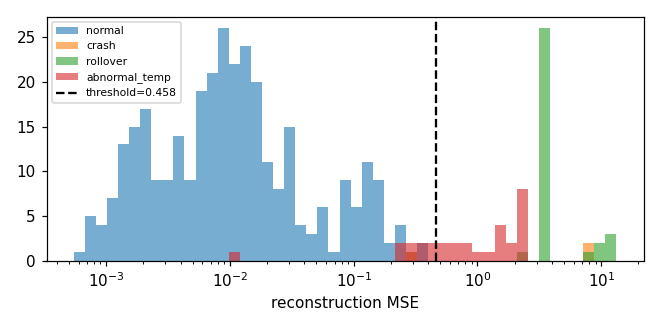

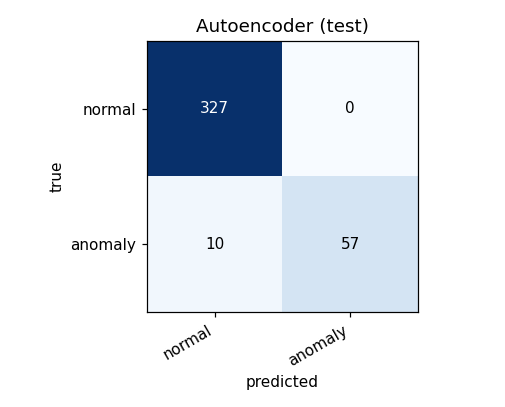

In [7]:
ae = run_training(mode="autoencoder", features_df=fx, epochs=200, verbose=0)
display(Image(str(ae["out_dir"] / "error_hist.png")))
display(Image(str(ae["out_dir"] / "confusion_matrix.png")))

## 5️⃣ Train — Classifier (optional)

চার class: `normal / crash / rollover / abnormal_temp`। Class imbalance-এর জন্য `class_weight` ব্যবহার। Event-এর **type** জানতে চাইলে এটি কাজে লাগে (যেমন SMS-এ "rollover" লেখা)।

CLI: `python scripts/train.py --mode classifier`

[data] 1888 windows (8 ambiguous dropped): {'normal': 1588, 'rollover': 142, 'abnormal_temp': 142, 'crash': 16}


2026-11-21 13:23:17.424340: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


[train] classifier: 242 epochs, 780 params, 18.7s -> /workspace/accident-ml/models/classifier
[test ] acc=0.995 macro-F1=0.945
[test ] confusion matrix ['normal', 'crash', 'rollover', 'abnormal_temp']:
[[327   0   0   0]
 [  1   2   0   0]
 [  0   0  33   0]
 [  1   0   0  30]]


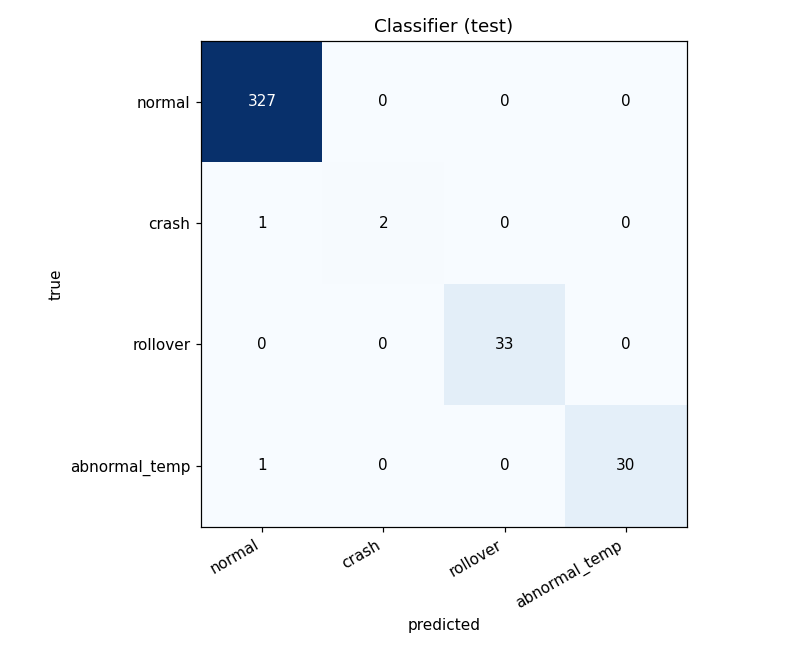

,precision,recall,f1-score,support
normal,0.994,1.000,0.997,327.0
crash,1.000,0.667,0.800,3.0
rollover,1.000,1.000,1.000,33.0
abnormal_temp,1.000,0.968,0.984,31.0


In [8]:
clf = run_training(mode="classifier", features_df=fx, epochs=300, verbose=0)
display(Image(str(clf["out_dir"] / "confusion_matrix.png")))
pd.DataFrame(clf["metrics"]["per_class"]).T.round(3)

## 6️⃣ Convert → int8 TFLite + 7️⃣ float vs int8

- `Optimize.DEFAULT` + representative dataset (training windows)
- `TFLITE_BUILTINS_INT8` only → weights, activations, **input ও output int8**
- TFLite interpreter (reference kernels) দিয়ে test set চালিয়ে float model-এর সাথে তুলনা
- Autoencoder-এর threshold int8 model-এর উপর আবার calibrate করা হয় (`kAnomalyThreshold`)

CLI: `python scripts/convert_tflite.py` এবং `python scripts/convert_tflite.py --model-dir models/classifier`

In [9]:
rep_ae = run_conversion(ROOT / "models/autoencoder")
print()
rep_clf = run_conversion(ROOT / "models/classifier")

INFO:tensorflow:Assets written to: /tmp/accident_sm_ubw93164/assets


INFO:tensorflow:Assets written to: /tmp/accident_sm_ubw93164/assets


W0000 00:00:1795245798.273533  672953 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1795245798.273590  672953 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
I0000 00:00:1795245798.278284  672953 mlir_graph_optimization_pass.cc:425] MLIR V1 optimization pass is not enabled
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


[tflite] /workspace/accident-ml/models/autoencoder/model_int8.tflite: 4632 bytes (4.5 KB)
[tflite] input {'dtype': 'int8', 'shape': [1, 12], 'scale': 0.04865536093711853, 'zero_point': -37}  output {'dtype': 'int8', 'shape': [1, 12], 'scale': 0.07280050218105316, 'zero_point': -72}
[tflite] tensor dtypes {'int8': 9, 'int32': 4}  ops ['FULLY_CONNECTED']
[tflite] fully int8 (int8 I/O, no float32 tensors): True
[verify] float: {'accuracy': 0.9746192893401016, 'precision': 1.0, 'recall': 0.8507462686567164, 'f1': 0.9193548387096774}
[verify] int8 : {'accuracy': 0.9771573604060914, 'precision': 1.0, 'recall': 0.8656716417910447, 'f1': 0.928}
[verify] float/int8 decision agreement: 0.997
[verify] threshold float=0.4583 int8=0.4441
[export] model_data.h, model_data.cc, model_config.h -> /workspace/accident-ml/models/autoencoder
[export] tensor arena suggestion: 8192 B (activations 62 B); tune with arena_used_bytes()

INFO:tensorflow:Assets written to: /tmp/accident_sm_yus05ujy/assets


INFO:tensorflow:Assets written to: /tmp/accident_sm_yus05ujy/assets


[tflite] /workspace/accident-ml/models/classifier/model_int8.tflite: 4384 bytes (4.3 KB)
[tflite] input {'dtype': 'int8', 'shape': [1, 12], 'scale': 0.03758903592824936, 'zero_point': -86}  output {'dtype': 'int8', 'shape': [1, 4], 'scale': 0.00390625, 'zero_point': -128}
[tflite] tensor dtypes {'int8': 8, 'int32': 3}  ops ['FULLY_CONNECTED', 'SOFTMAX']
[tflite] fully int8 (int8 I/O, no float32 tensors): True
[verify] float: {'accuracy': 0.9949238578680203}
[verify] int8 : {'accuracy': 0.9949238578680203}
[verify] float/int8 decision agreement: 1.000
[export] model_data.h, model_data.cc, model_config.h -> /workspace/accident-ml/models/classifier
[export] tensor arena suggestion: 8192 B (activations 60 B); tune with arena_used_bytes()


W0000 00:00:1795245798.846246  672953 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1795245798.846270  672953 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


In [10]:
rows = []
for name, r in [("autoencoder", rep_ae), ("classifier", rep_clf)]:
    for kind in ["float", "int8"]:
        rows.append({"model": name, "type": kind, **{k: round(v, 4) for k, v in r[kind].items()}})
summary = pd.DataFrame(rows)
display(summary)
print({n: (r["tflite_bytes"], r["tflite"]["fully_int8"], r["tflite"]["ops"]) for n, r in
       [("autoencoder", rep_ae), ("classifier", rep_clf)]})

,model,type,accuracy,precision,recall,f1
0,autoencoder,float,0.9746,1.0,0.8507,0.9194
1,autoencoder,int8,0.9772,1.0,0.8657,0.9280
2,classifier,float,0.9949,NaN,NaN,NaN
3,classifier,int8,0.9949,NaN,NaN,NaN


{'autoencoder': (4632, True, ['FULLY_CONNECTED']), 'classifier': (4384, True, ['FULLY_CONNECTED', 'SOFTMAX'])}


## 8️⃣ Export — TFLite Micro header files

`models/autoencoder/` এ তৈরি হয়েছে:
- `model_int8.tflite` — int8 model
- `model_data.h` / `model_data.cc` — xxd-style `alignas(16)` C array (`g_model_data`, `g_model_data_len`)
- `model_config.h` — scaler mean/std, clip, input/output quant params, threshold, window config, `kTensorArenaSize`

এই তিনটি file `../firmware/` (যেমন `firmware/include/` বা `firmware/src/`) এ copy করতে হবে। Firmware-এ প্রতি 0.5 s-এ: 12 feature → standardize → int8 quantize → `Invoke()` → dequantize → MSE > `kAnomalyThreshold` হলে alert।

In [11]:
cfg = (ROOT / "models/autoencoder/model_config.h").read_text()
print(cfg)
print("\n".join((ROOT / "models/autoencoder/model_data.cc").read_text().splitlines()[:8]), "\n  ...")

// Auto-generated by convert_tflite.py on 2026-11-21 13:23 - do not edit.
// Constants that MUST match training (scripts/features.py + scaler.json).
#ifndef ACCIDENT_MODEL_CONFIG_H_
#define ACCIDENT_MODEL_CONFIG_H_

#include <stdint.h>

// ---- sampling / windowing ----
constexpr int kSampleRateHz = 100;
constexpr int kWindowSize = 100;   // samples per inference window (1 s)
constexpr int kWindowStep = 50;   // run inference every 0.5 s
constexpr float kTempAlarmC = 60.0f; // optional hard rule backup

// ---- features (same order as training) ----
constexpr int kNumFeatures = 12;
//   [ 0] acc_mag_mean
//   [ 1] acc_mag_std
//   [ 2] acc_mag_max
//   [ 3] jerk_max
//   [ 4] gyro_mag_mean
//   [ 5] gyro_mag_max
//   [ 6] tilt_deg
//   [ 7] temp_mean
//   [ 8] temp_slope
//   [ 9] vib_mean
//   [10] vib_rms
//   [11] vib_peak

// z[i] = clamp((x[i] - kFeatureMean[i]) / kFeatureStd[i], -kFeatureClip, kFeatureClip)
constexpr float kFeatureClip = 8.0f;
static const float kFeatureMean[kNum

In [12]:
# Sanity: emulate the MCU math for one window per class using only the exported constants
import re
def arr(name):
    m = re.search(name + r"\[kNumFeatures\]\s*=\s*\{([^}]*)\}", cfg)
    return np.array([float(x.strip().rstrip("f")) for x in m.group(1).split(",")], np.float32)
def const(name):
    return float(re.search(r"\b" + name + r"\s*=\s*([-0-9.e]+)", cfg).group(1))
mean, std, clip = arr("kFeatureMean"), arr("kFeatureStd"), const("kFeatureClip")
thr = const("kAnomalyThreshold")

from convert_tflite import Int8Runner
import tensorflow as tf
runner = Int8Runner((ROOT / "models/autoencoder/model_int8.tflite").read_bytes(), tf)
for lab in F.LABELS:
    x = fx[fx.label == lab][F.FEATURE_NAMES].to_numpy(np.float32)
    if len(x) == 0:
        continue
    x = x[len(x) // 2: len(x) // 2 + 1]
    z = np.clip((x - mean) / std, -clip, clip)
    err = float(np.mean((runner(z) - z) ** 2))
    print(f"{lab:14s} score={err:8.4f}  alarm={err > thr}")

normal         score=  0.0118  alarm=False
crash          score=  8.9376  alarm=True
rollover       score=  3.4424  alarm=True
abnormal_temp  score=  3.1530  alarm=True


## ✅ পরবর্তী ধাপ (Next steps)

1. ESP32-S3 + MPU6050 + DS18B20 + vibration sensor দিয়ে **real data** log করুন: `python scripts/collect_data.py --serial COM5 --label normal --scenario cruising --seconds 300 --out data/raw/real_normal.csv`
2. Real normal driving data দিয়ে autoencoder retrain → threshold আবার calibrate
3. নিরাপদভাবে (dummy/test rig, drop test) impact data সংগ্রহ করে validate
4. `convert_tflite.py` চালিয়ে নতুন header `../firmware/`-এ copy

> ⚠️ Simulated data ≠ real crash data. এই model কোনো জীবন-রক্ষাকারী system-এ সরাসরি ব্যবহার করবেন না।